# heaven: comparable social media reporting across markets

Independent case study based on public data · not affiliated with or endorsed by heaven or Hopscotch Groupe.

**Part 1 - PUBLIC DATA**: beauty brands' interest by language (Wikipedia), social-network use by country (Eurostat),
a small real social-listening sample (Mastodon), official brand accounts on Bluesky.
**Part 2 - SIMULATED**: a fictitious multi-market beauty retailer, 5 markets x 5 platforms: harmonised KPIs, the 8 hidden
situations and how they are found, sentiment and themes, influencer communities, recommendations by market.

Every table below is read from `data/public/` or `data/processed/` (built by `src/fetch_public.py`, `src/simulate.py`
and `src/run_sql.py`).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
PUB, PROC = ROOT / "data" / "public", ROOT / "data" / "processed"
F = json.loads((PROC / "facts.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
PLUM = "#6B2D5C"; print("collected on", F["collected_on"])

collected on 2026-11-17


## Part 1 - PUBLIC DATA
### 1.1 Social-network use by country (Eurostat `isoc_ci_ac_i`, `I_IUSNET`)

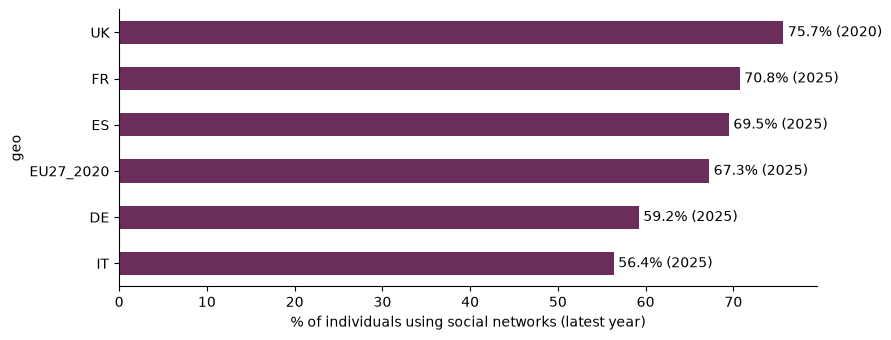

In [2]:
e = pd.read_csv(PUB / "eurostat_social_use.csv")
last = e.sort_values("year").groupby("geo").last().sort_values("pct_individuals")
ax = last.pct_individuals.plot.barh(color=PLUM); ax.set_xlabel("% of individuals using social networks (latest year)")
for i, (g, r) in enumerate(last.iterrows()): ax.text(r.pct_individuals + .5, i, f"{r.pct_individuals:.1f}% ({int(r.year)})", va="center")
plt.show()

The UK has no Eurostat figure after 2020 (last year it is covered); it is shown but not compared with 2025 values.

### 1.2 Interest by language (Wikipedia page views per million views of each edition)

In [3]:
w = pd.read_csv(PUB / "wikipedia_pageviews.csv")
full = w.groupby(["kind", "entity"]).lang.nunique(); keep = full[full == 5].index
w5 = w[w.set_index(["kind", "entity"]).index.isin(keep)]
brand = w5[w5.kind == "brand"].pivot_table(index="entity", columns="lang", values="per_million", aggfunc="mean").round(2)
print("brands present in all 5 editions:", len(brand)); brand

brands present in all 5 editions: 6


lang,de,en,es,fr,it
entity,,,,,
Fenty Beauty,0.55,1.31,1.18,1.02,0.38
La Roche-Posay,0.70,0.41,0.50,4.90,0.58
Lancôme,0.49,0.65,0.97,1.88,0.66
Maybelline,0.54,0.15,0.21,0.82,0.64
Nivea,6.50,1.30,3.29,2.84,2.44
Rimmel,0.08,0.17,0.36,0.47,0.30


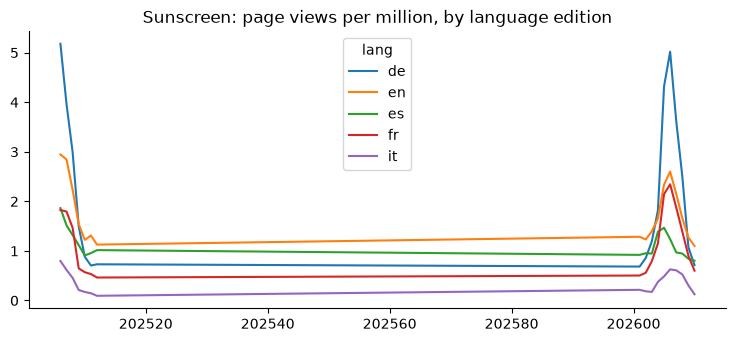

In [4]:
t = w5[w5.kind == "topic"].pivot_table(index="month", columns=["entity", "lang"], values="per_million", aggfunc="sum")
ax = t["Sunscreen"].plot(title="Sunscreen: page views per million, by language edition"); ax.set_xlabel(""); plt.show()

Reading: interest is seasonal (sunscreen peaks in summer in every language) and brand interest differs by language,
so one European average would hide market differences. Limits: the English edition is global, not a UK measure;
page views measure curiosity, not purchases.

### 1.3 Mini social listening on Mastodon (public hashtag timelines)

1435 posts collected, 1168 in the last 12 months, 9 hashtags


,posts,median interactions
tag,,
beauté,200,0.0
skincare,200,0.0
beauty,199,0.0
makeup,194,0.0
skincareroutine,161,0.0
maquillaje,94,0.0
hautpflege,61,0.0
maquillage,46,1.0
trucco,13,0.0


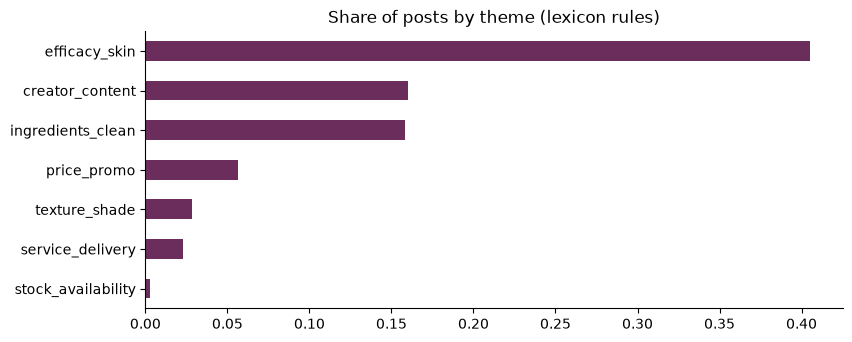

In [5]:
m = pd.read_csv(PUB / "mastodon_sample.csv")
m12 = m[m.date >= str(pd.Timestamp(F["collected_on"]) - pd.DateOffset(months=12))[:10]]
print(f"{len(m)} posts collected, {len(m12)} in the last 12 months, {m.tag.nunique()} hashtags")
th = [c for c in m12.columns if c.startswith("theme_")]
summary = pd.DataFrame({"posts": m12.groupby("tag").size(), "median interactions": m12.assign(i=m12.favourites + m12.reblogs + m12.replies).groupby("tag").i.median()})
display(summary.sort_values("posts", ascending=False))
m12[th].mean().sort_values().rename(lambda c: c.replace("theme_", "")).plot.barh(color=PLUM, title="Share of posts by theme (lexicon rules)"); plt.show()

Volumes are small and the platform's audience is not representative of beauty consumers; this sample only shows that
the listening pipeline (collection, language, themes, sentiment) runs on real public posts. No text or account is kept.

### 1.4 Official brand accounts on Bluesky (handle = brand domain, verified by DNS)

In [6]:
b = pd.read_csv(PUB / "bluesky_accounts.csv"); b[["entity", "handle", "on_bluesky"] + [c for c in ["followers", "posts_total"] if c in b]]

,entity,handle,on_bluesky,followers,posts_total
0,Maybelline,maybelline.com,False,NaN,NaN
1,Lancôme,lancome.com,False,NaN,NaN
2,NYX Professional Makeup,nyxcosmetics.com,False,NaN,NaN
3,Garnier,garnier.com,False,NaN,NaN
4,Nivea,nivea.com,False,NaN,NaN
5,CeraVe,cerave.com,False,NaN,NaN
6,La Roche-Posay,laroche-posay.com,False,NaN,NaN
7,Clinique,clinique.com,False,NaN,NaN
8,Rimmel,rimmellondon.com,False,NaN,NaN
9,Fenty Beauty,fentybeauty.com,False,NaN,NaN


In [7]:
yt = PUB / "youtube_brand_videos.csv"
print("YouTube panel available" if yt.exists() else "No YouTube API key: YouTube panel not collected (fallback: Wikipedia, Mastodon, Bluesky).")

No YouTube API key: YouTube panel not collected (fallback: Wikipedia, Mastodon, Bluesky).


## Part 2 - SIMULATED account
### 2.1 Data quality first: what the harmonisation corrects

In [8]:
for t in ["dq_definition", "dq_sponsored", "dq_timezone", "dq_duplicates"]:
    print(t); display(pd.read_csv(PROC / f"{t}.csv").round(3))

dq_definition


,platform,change_date,raw_views_per_reach_before,raw_views_per_reach_after,harmonised_views_per_reach_before,harmonised_views_per_reach_after,share_missing_raw_before
0,Instagram,2026-02-01,0.809,1.804,1.815,1.804,0.551


dq_sponsored


,market,organic_label_with_spend,sponsored_posts,share_mislabelled
0,DE,0,192,0.00
1,ES,0,222,0.00
2,FR,0,234,0.00
3,IT,228,228,0.17
4,UK,0,224,0.00


dq_timezone


,market,timezone_of_export,market_timezone,median_hour_exported,median_hour_local,share_before_8_exported
0,DE,UTC,Europe/Berlin,13.0,15.0,0.119
1,ES,Europe/Madrid,Europe/Madrid,15.0,15.0,0.023
2,FR,Europe/Paris,Europe/Paris,15.0,15.0,0.018
3,IT,Europe/Rome,Europe/Rome,14.0,14.0,0.018
4,UK,Europe/London,Europe/London,15.0,15.0,0.017


dq_duplicates


,platform,global_posts,rows_in_exports,extra_rows,reach_counted_twice
0,Instagram,51,255,204,112489388.0


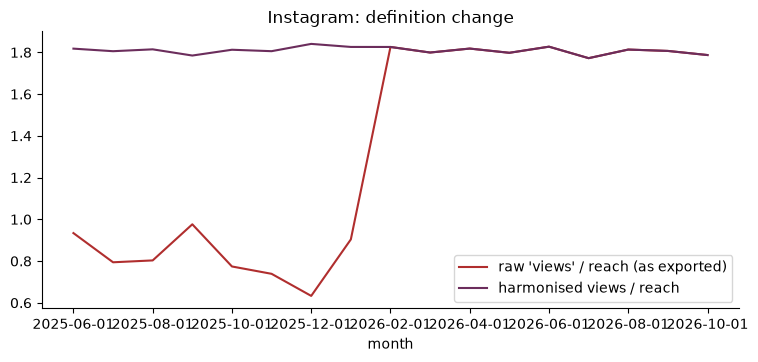

In [9]:
k = pd.read_csv(PROC / "kpi_month_mp.csv"); ig = k[k.platform == "Instagram"].groupby("month")[["views_raw", "views", "reach"]].sum()
ax = (ig.views_raw / ig.reach).plot(label="raw 'views' / reach (as exported)", color="#B02E2E")
(ig.views / ig.reach).plot(ax=ax, label="harmonised views / reach", color=PLUM); ax.legend(); ax.set_title("Instagram: definition change"); plt.show()

### 2.2 Monthly KPIs by market (harmonised, organic engagement)

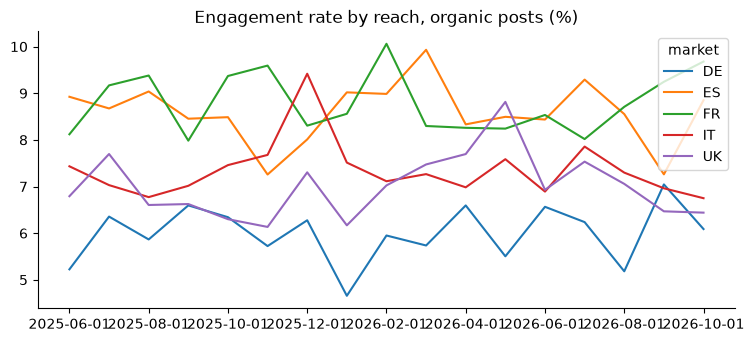

,reach,engagements,er_reach_org,net_sentiment,followers_end
market,,,,,
DE,10743640.0,556064.0,0.061,24.667,842307.0
ES,17280760.0,1381022.0,0.089,32.308,1225373.0
FR,14595669.0,1113051.0,0.097,2.101,1466557.0
IT,12457479.0,589855.0,0.067,37.712,827056.0
UK,18631627.0,1021636.0,0.064,41.102,1378817.0


In [10]:
km = pd.read_csv(PROC / "kpi_month_market.csv")
p = km.pivot(index="month", columns="market", values="er_reach_org") * 100
ax = p.plot(title="Engagement rate by reach, organic posts (%)"); ax.set_xlabel(""); plt.show()
km[km.month == "2026-10-01"].set_index("market")[["reach", "engagements", "er_reach_org", "net_sentiment", "followers_end"]].round(3)

### 2.3 The 8 hidden situations: detection and decision

In [11]:
det = pd.read_csv(PROC / "detection.csv"); display(det[["event_id", "event", "detected", "where", "evidence", "decision"]])
truth = PROC / "detection_vs_truth.csv"
if truth.exists():
    s = pd.read_csv(truth); print(f"Detection rate against the hidden answer key: {s.found.sum()}/{len(s)}")

,event_id,event,detected,where,evidence,decision
0,1,metric_definition_change,True,Instagram from 2026-02-01,raw views per reach x2.2 after the break; harm...,use harmonised views (impressions before the c...
1,2,sponsored_mixed_in_organic,True,IT,228 posts labelled organic have ad spend; medi...,sponsored = tool label OR ad spend > 0; organi...
2,3,timezone_utc_export,True,DE,12% of posts before 08:00 as exported vs 2% el...,convert every export to market local time befo...
3,4,false_signal_contest,True,ES Instagram,followers +37% in 2026-03; ER per follower -19...,NOT raised as a content problem: report ER per...
4,5,suspect_creator,True,creator_022,"creator_022: score 0, max weekly growth +163%,...",excluded from recommendations until audience i...
5,6,negative_sentiment_spike,True,FR 2026-10,net sentiment 2 vs 33 usual (z -5.2); stock / ...,attention point: stock-out of a hero product; ...
6,7,format_effect_by_market,True,"short video ahead: ES, FR; carousel ahead: DE",DE x0.57 [0.53-0.62]; ES x1.19 [1.1-1.28]; FR ...,"format mix set per market, not one global rule"
7,8,global_post_duplicates,True,Instagram,51 global posts appear 255 times; group reach ...,count each native post id once in group totals...


Detection rate against the hidden answer key: 8/8


In [12]:
a = pd.read_csv(PROC / "anomalies.csv")
print(f"{a.flagged.sum()} flags out of {len(a)} KPI-months screened (robust z, |z| >= 3.5)")
a[a.flagged].groupby("metric").size()

34 flags out of 1559 KPI-months screened (robust z, |z| >= 3.5)


metric
er_followers_org        7
follower_growth         8
net_sentiment           8
views_raw_per_reach    11
dtype: int64

**The false signal (Spain)**: engagement per follower falls after the giveaway, engagement per reach does not: the
denominator moved (followers who do not engage), not the content. The rule therefore does **not** raise a content issue.

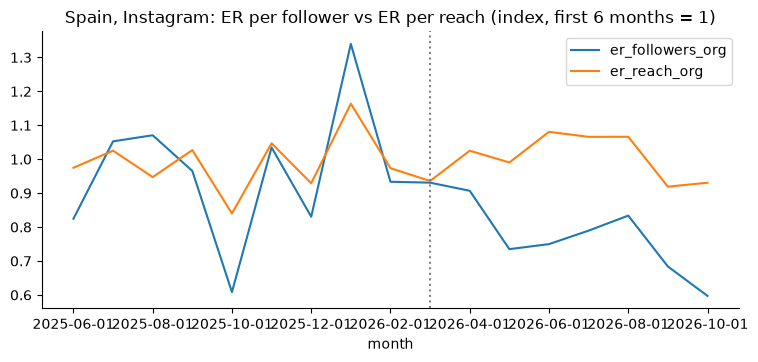

In [13]:
es = k[(k.market == "ES") & (k.platform == "Instagram")].set_index("month")
ax = (es[["er_followers_org", "er_reach_org"]] / es[["er_followers_org", "er_reach_org"]].iloc[:6].median()).plot(
    title="Spain, Instagram: ER per follower vs ER per reach (index, first 6 months = 1)")
ax.axvline(list(es.index).index("2026-03-01"), color="grey", ls=":"); plt.show()

### 2.4 Formats by market

In [14]:
pd.read_csv(PROC / "format_by_market.csv")

,market,short_vs_carousel,ci_low,ci_high,n_short,n_carousel
0,DE,0.57,0.53,0.62,123,96
1,ES,1.19,1.10,1.28,108,89
2,FR,1.38,1.27,1.51,120,88
3,IT,1.00,0.90,1.10,132,94
4,UK,0.90,0.83,0.98,122,103


### 2.5 Sentiment and themes (lexicon in FR / EN / DE / ES / IT, no LLM)

Method: positive and negative word lists per language, a negation flips the next 2 words, a few emojis;
score = (pos - neg) / (pos + neg). Themes are keyword rules. Limits: no irony, short lists, and the agreement below is
measured on **synthetic** comments built from templates, so it is optimistic: real comments need a hand-labelled sample.

In [15]:
c = pd.read_csv(PROC / "comments_scored.csv")
print(f"agreement with labels: {(c.label == c.label_true).mean():.0%}")
display(pd.crosstab(c.label_true, c.label, normalize="index").round(2))
c.groupby("lang").apply(lambda x: (x.label == x.label_true).mean(), include_groups=False).round(3)

agreement with labels: 90%


label,negative,neutral,positive
label_true,,,
negative,0.74,0.23,0.03
neutral,0.00,1.00,0.00
positive,0.00,0.11,0.89


lang
de    0.792
en    0.956
es    0.937
fr    0.850
it    0.932
dtype: float64

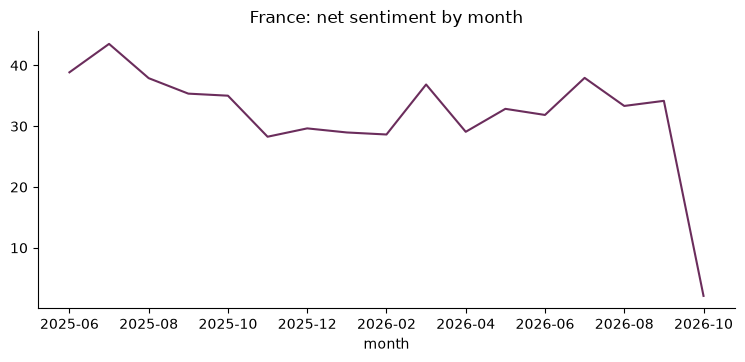

,theme_price_promo,theme_stock_availability,theme_efficacy_skin,theme_texture_shade,theme_ingredients_clean,theme_creator_content,theme_service_delivery
month,,,,,,,
2026-07,0.19,0.56,0.06,0.0,0.0,0.0,0.0
2026-08,0.19,0.52,0.04,0.0,0.0,0.0,0.0
2026-09,0.10,0.29,0.33,0.0,0.0,0.0,0.0
2026-10,0.08,0.76,0.06,0.0,0.0,0.0,0.0


In [16]:
c["month"] = c.date.str[:7]
fr = c[c.market == "FR"].groupby("month").apply(lambda x: 100 * ((x.label == "positive").mean() - (x.label == "negative").mean()), include_groups=False)
ax = fr.plot(title="France: net sentiment by month", color=PLUM); plt.show()
neg = c[(c.market == "FR") & (c.label == "negative")]
neg.groupby("month")[[x for x in c.columns if x.startswith("theme_")]].mean().tail(4).round(2)

### 2.6 Influencer communities (mention graph, Louvain, PageRank, betweenness)

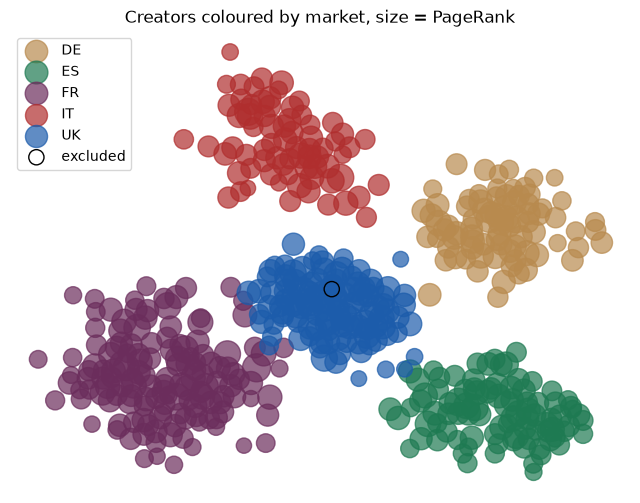

,community,size,main_market,main_market_share,main_niche,main_niche_share,median_er,macro_share,mention_our_account_share,hub
0,0,91,ES,1.0,make-up,0.41,0.0436,0.10,0.76,creator_024
1,1,81,DE,1.0,skincare,0.48,0.0415,0.07,0.58,creator_326
2,2,73,IT,1.0,skincare,0.44,0.0404,0.07,0.75,creator_332
3,3,71,UK,1.0,skincare,0.52,0.0405,0.11,0.61,creator_030
4,4,47,FR,1.0,make-up,1.00,0.0465,0.04,0.81,creator_262
5,5,45,FR,1.0,skincare,1.00,0.0379,0.07,0.71,creator_287
6,6,42,UK,1.0,make-up,1.00,0.0401,0.07,0.55,creator_497
7,7,27,FR,1.0,lifestyle,1.00,0.0351,0.22,0.81,creator_175
8,8,23,FR,1.0,hair & fragrance,1.00,0.0393,0.17,0.78,creator_366


In [17]:
net = pd.read_csv(PROC / "creator_network.csv"); comm = pd.read_csv(PROC / "communities.csv")
fig, ax = plt.subplots(figsize=(8, 6))
cols = {"FR": "#6B2D5C", "UK": "#1C5CAB", "DE": "#B88A4E", "ES": "#1E7A52", "IT": "#B02E2E"}
for mk, g in net.groupby("market"):
    ax.scatter(g.x, g.y, s=8 + 400 * g.pagerank / net.pagerank.max(), c=cols[mk], alpha=.7, label=mk)
sus = net[net.authenticity_score < 50]; ax.scatter(sus.x, sus.y, s=120, facecolors="none", edgecolors="black", label="excluded")
ax.legend(); ax.set_axis_off(); ax.set_title("Creators coloured by market, size = PageRank"); plt.show()
comm

In [18]:
pd.read_csv(PROC / "market_profiles.csv")

,market,creators,nano_share,micro_share,macro_share,median_er_nano,median_er_micro,median_er_macro,top_niche,communities,cross_market_share,share_of_voice_3m
0,DE,81,0.54,0.38,0.07,0.0472,0.0323,0.0200,skincare,1,0.073,0.149
1,ES,91,0.51,0.40,0.10,0.0518,0.0349,0.0193,make-up,1,0.073,0.299
2,FR,142,0.48,0.42,0.11,0.0562,0.0327,0.0164,make-up,4,0.068,0.338
3,IT,73,0.52,0.41,0.07,0.0545,0.0338,0.0181,skincare,1,0.076,0.308
4,UK,113,0.50,0.40,0.10,0.0563,0.0346,0.0213,make-up,2,0.130,0.176


In [19]:
cs = pd.read_csv(PROC / "creator_scores.csv")
display(cs.sort_values("authenticity_score").head(3)[["creator_id", "market", "tier", "max_weekly_growth", "er_followers", "tier_median_er", "audience_own_market", "comments_per_like", "authenticity_score"]])
pd.read_csv(PROC / "creator_shortlist.csv")

,creator_id,market,tier,max_weekly_growth,er_followers,tier_median_er,audience_own_market,comments_per_like,authenticity_score
21,creator_022,UK,macro,1.629898,0.0028,0.01905,0.210,0.0060,0
495,creator_496,UK,micro,0.018802,0.0314,0.03380,0.645,0.0298,100
494,creator_495,IT,micro,0.017623,0.0284,0.03380,0.764,0.0578,100


,market,creator_id,tier,niche,platform,followers,er_followers,engagements_per_eur,authenticity_score,community
0,DE,creator_218,nano,skincare,TikTok,9133,0.0556,7.359345,100,1
1,DE,creator_354,nano,make-up,TikTok,14634,0.0692,7.233377,100,1
2,DE,creator_101,nano,skincare,Instagram,13275,0.0824,7.057161,100,1
3,ES,creator_100,nano,make-up,Instagram,19277,0.1118,9.840953,100,0
4,ES,creator_297,micro,hair & fragrance,Instagram,29872,0.0426,8.716077,100,0
5,ES,creator_295,nano,skincare,Instagram,5803,0.0866,7.390291,100,0
6,FR,creator_407,nano,skincare,Instagram,4311,0.0874,11.081806,100,5
7,FR,creator_159,nano,skincare,TikTok,8658,0.0742,10.888536,100,5
8,FR,creator_492,nano,skincare,Instagram,12069,0.0910,10.874050,100,5
9,IT,creator_322,nano,skincare,TikTok,24621,0.0856,11.034333,100,2


### 2.7 Recommendations by market (October 2026)

| Market | Lever | Test next | KPI to watch |
|---|---|---|---|
| France | answer stock questions with a restock date; more short video on Instagram | tutorial short videos with nano make-up creators | net sentiment back to usual |
| United Kingdom | keep the format mix; seed the skincare community (low share of voice) | micro skincare creators | share of voice |
| Germany | carousel first on Instagram; publish in the evening, local time | educational carousels | engagement rate by reach |
| Spain | report engagement by reach, not by followers, after the giveaway | re-engagement of giveaway followers | ER by reach, churn |
| Italy | fix the sponsored flag at source; reduce the paid share | lower paid share for two weeks | organic reach rate, cost per engagement |

What we cannot conclude: sentiment *levels* across languages, and any format effect before a test confirms it.